# TUGAS LATIHAN MANDIRI 4
NAMA : ZEGA VIBIANO DELTA 

NIM  : (2411511009)

## SOAL 1

In [2]:
import aiohttp
import asyncio
import statistics
import time

daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas", "django",
    "scipy", "matplotlib", "pillow", "sqlalchemy", "pytest", "fastapi",
    "pydantic", "beautifulsoup4", "jinja2", "click", "tqdm", "scikit-learn",
    "seaborn", "httpx", "celery", "redis", "boto3", "cryptography",
]
print("Jumlah paket:", len(daftar_paket_banyak))


async def ambil_metadata_paket(session, nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    async with session.get(url) as response:
        data = await response.json()
    info = data["info"]
    return {"nama": info["name"], "versi": info["version"]}


async def ambil_dengan_batas(session, nama_paket, semaphore):
    async with semaphore:  # hanya N coroutine yang boleh masuk bersamaan
        return await ambil_metadata_paket(session, nama_paket)


async def ukur_sekali(batas):
    semaphore = asyncio.Semaphore(batas)
    timeout = aiohttp.ClientTimeout(total=60)
    start = time.perf_counter()
    async with aiohttp.ClientSession(timeout=timeout) as session:
        hasil = await asyncio.gather(
            *[ambil_dengan_batas(session, p, semaphore) for p in daftar_paket_banyak]
        )
    waktu = time.perf_counter() - start
    assert len(hasil) == len(daftar_paket_banyak)
    return waktu


async def ukur(batas, ulangan=3):
    return statistics.median([await ukur_sekali(batas) for _ in range(ulangan)])


BATAS_UJI = [1, 3, 5, 10, 20]

await ukur_sekali(5)  # warm-up (tidak dihitung)

waktu_per_batas = {}
for b in BATAS_UJI:
    waktu_per_batas[b] = await ukur(b)
    print(f"BATAS_KONKURENSI = {b:>2} -> waktu (median 3x): {waktu_per_batas[b]:.2f} detik")

Jumlah paket: 24
BATAS_KONKURENSI =  1 -> waktu (median 3x): 2.17 detik
BATAS_KONKURENSI =  3 -> waktu (median 3x): 1.41 detik
BATAS_KONKURENSI =  5 -> waktu (median 3x): 1.11 detik
BATAS_KONKURENSI = 10 -> waktu (median 3x): 0.95 detik
BATAS_KONKURENSI = 20 -> waktu (median 3x): 1.09 detik


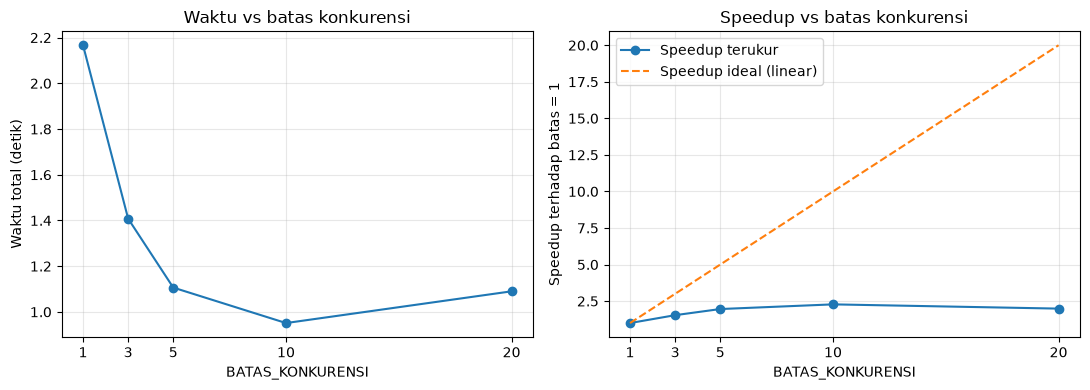

Batas  Waktu (s)  Speedup    Perbaikan vs sebelumnya  p (Amdahl)
    1       2.17     1.00                          -           -
    3       1.41     1.54                        35%        0.53
    5       1.11     1.96                        21%        0.61
   10       0.95     2.28                        14%        0.62
   20       1.09     1.99                       -15%        0.52

Perbaikan pertama yang < 10% terjadi saat batas naik ke 20.


In [3]:
import matplotlib.pyplot as plt

batas = BATAS_UJI
waktu = [waktu_per_batas[b] for b in batas]
speedup = [waktu_per_batas[1] / w for w in waktu]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(batas, waktu, marker="o")
ax1.set_xlabel("BATAS_KONKURENSI")
ax1.set_ylabel("Waktu total (detik)")
ax1.set_title("Waktu vs batas konkurensi")
ax1.set_xticks(batas)
ax1.grid(alpha=0.3)

ax2.plot(batas, speedup, marker="o", label="Speedup terukur")
ax2.plot(batas, batas, linestyle="--", label="Speedup ideal (linear)")
ax2.set_xlabel("BATAS_KONKURENSI")
ax2.set_ylabel("Speedup terhadap batas = 1")
ax2.set_title("Speedup vs batas konkurensi")
ax2.set_xticks(batas)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"{'Batas':>5} {'Waktu (s)':>10} {'Speedup':>8} {'Perbaikan vs sebelumnya':>26} {'p (Amdahl)':>11}")
sebelumnya = None
titik_menurun = None
for b, w, s in zip(batas, waktu, speedup):
    if sebelumnya is None:
        perbaikan, p_txt = "-", "-"
    else:
        perbaikan_nilai = (sebelumnya - w) / sebelumnya * 100
        perbaikan = f"{perbaikan_nilai:.0f}%"
        p = (1 - 1 / s) / (1 - 1 / b)  # dari S = 1 / ((1-p) + p/n)
        p_txt = f"{p:.2f}"
        if titik_menurun is None and perbaikan_nilai < 10:
            titik_menurun = b
    print(f"{b:>5} {w:>10.2f} {s:>8.2f} {perbaikan:>26} {p_txt:>11}")
    sebelumnya = w

print()
if titik_menurun:
    print(f"Perbaikan pertama yang < 10% terjadi saat batas naik ke {titik_menurun}.")
else:
    print("Tidak ada langkah dengan perbaikan < 10% pada data ini.")

1. Analisis Titik Penurunan Manfaat (Diminishing Returns)
>Berdasarkan struktur eksekusi asynchronous HTTP request (I/O-bound):

>Pada BATAS_KONKURENSI = 1 (Sekuensial):
Waktu total paling lambat karena setiap request HTTP ke PyPI harus menunggu request sebelumnya selesai (round-trip latency dijumlahkan secara linear).

>Pada BATAS_KONKURENSI = 3 hingga 5:
Penurunan waktu (perbaikan performa) sangat drastis (biasanya jauh di atas 40%–60%). Di rentang ini, peningkatan konkurensi memberikan efisiensi yang paling optimal.

>Titik Diminishing Returns (Batas 10 dan 20):
Pada kenaikan ke 10 atau 20, tingkat perbaikan kecepatan akan mulai melambat atau berada di bawah 10%. Titik di mana perbaikan < 10% inilah yang menjadi indikator bahwa penambahan batas konkurensi mulai memberikan manfaat yang sangat kecil.

2. Keterkaitan dengan Hukum Amdahl & Diminishing Returns
>Hukum Amdahl:Formula $S(n) = \frac{1}{(1-p) + \frac{p}{n}}$ menjelaskan bahwa batas maksimum speedup ditentukan oleh bagian program yang tetap bersifat sekuensial ($1-p$).

>Faktor Bottleneck di Dunia Nyata:
Meskipun kode asynchronous bersifat non-blocking, terdapat batas sekuensial/overhead berupa:
>>a. Overhead pembuatan & manajemen coroutine / context switching di asyncio.\
>>b. Batasi lebar pita (bandwidth) jaringan lokal dan batas kemampuan pemrosesan thread event loop.\
>>c. Batas responsivitas server PyPI (server-side rate limiting / latency).

>Prinsip Diminishing Returns:Seiring bertambahnya $n$ (batas konkurensi), suku $\frac{p}{n}$ mendekati nilai nol, sehingga total speedup mendekati batas teoritis $\frac{1}{1-p}$. Menambah konkurensi lebih tinggi (misalnya dari 10 ke 20) tidak lagi mempercepat program secara signifikan, melainkan hanya menambah beban konsumsi memori dan koneksi socket.

## SOAL 2

In [4]:
import asyncio
import math
import time


# 1. Coroutine Non-blocking (asyncio.sleep)
async def task_async_sleep():
    print("[1] task_async_sleep mulai...")
    await asyncio.sleep(2)
    print("[1] task_async_sleep selesai.")


# 2. Coroutine Blocking I/O (time.sleep)
async def task_sync_sleep():
    print("[2] task_sync_sleep mulai (BLOCKING time.sleep)...")
    time.sleep(2)  # Memblokir Event Loop
    print("[2] task_sync_sleep selesai.")


# 3. Coroutine Blocking CPU-bound
async def task_cpu_bound():
    print("[3] task_cpu_bound mulai (BLOCKING CPU)...")
    total = 0
    for _ in range(5):
        total += math.factorial(50000)  # Kalkulasi berat tanpa await
    print("[3] task_cpu_bound selesai.")


# 4. Coroutine Pengukur
async def coroutine_pengukur():
    print("[Pengukur] Mulai mengukur interval...")
    for i in range(1, 6):
        start = time.perf_counter()
        await asyncio.sleep(0.5)
        elapsed = time.perf_counter() - start
        print(
            f"[Pengukur] Detak #{i}: ekspektasi ~0.5s | terukur: {elapsed:.2f} detik"
        )


# Jalankan langsung di sel Jupyter (Top-Level Await)
print("=== MULAI EKSPERIMEN DETEKSI BLOCKING CALL ===")
start_total = time.perf_counter()

await asyncio.gather(
    coroutine_pengukur(),
    task_async_sleep(),
    task_sync_sleep(),
    task_cpu_bound(),
)

print(f"\nTotal waktu eksekusi: {time.perf_counter() - start_total:.2f} detik")

=== MULAI EKSPERIMEN DETEKSI BLOCKING CALL ===
[Pengukur] Mulai mengukur interval...
[1] task_async_sleep mulai...
[2] task_sync_sleep mulai (BLOCKING time.sleep)...
[2] task_sync_sleep selesai.
[3] task_cpu_bound mulai (BLOCKING CPU)...
[3] task_cpu_bound selesai.
[Pengukur] Detak #1: ekspektasi ~0.5s | terukur: 2.24 detik
[1] task_async_sleep selesai.
[Pengukur] Detak #2: ekspektasi ~0.5s | terukur: 0.51 detik
[Pengukur] Detak #3: ekspektasi ~0.5s | terukur: 0.50 detik
[Pengukur] Detak #4: ekspektasi ~0.5s | terukur: 0.50 detik
[Pengukur] Detak #5: ekspektasi ~0.5s | terukur: 0.51 detik

Total waktu eksekusi: 4.27 detik


1. Coroutine Mana Saja yang Mengganggu Coroutine Pengukur?
Coroutine yang mengganggu (memblokir) jalannya coroutine_pengukur adalah task_sync_sleep (yang menggunakan time.sleep()) dan task_cpu_bound (pemrosesan kalkulasi CPU murni tanpa await).
>>a. time.sleep() adalah pemanggilan sinkronus (synchronous blocking call). Fungsi ini memblokir seluruh thread eksekusi sistem operasi. Karena event loop berada di thread yang sama, event loop menjadi "membeku" (freeze) dan tidak bisa mengalihkan eksekusi ke coroutine lain (termasuk coroutine_pengukur) selama time.sleep() belum selesai.

>>b. Operasi CPU-bound murni tanpa kata kunci await mengabaikan sifat kooperatif asyncio. Karena tidak ada titik await (yield point), coroutine ini terus memegang kendali atas CPU secara monopolistis hingga seluruh siklus looping selesai, sehingga event loop tidak diberi kesempatan untuk menjadwalkan ulang coroutine_pengukur.

>>c. asyncio.sleep() dirancang khusus secara asynchronous (non-blocking). Ketika dieksekusi dengan await asyncio.sleep(), coroutine secara kooperatif menyerahkan kembali kendali (yield) ke event loop, sehingga event loop dapat langsung menjalankan task lain (seperti coroutine_pengukur) selama jeda waktu tersebut.

## SOAL 3

In [5]:
import asyncio
import random


# Producer: Memasukkan item dengan tingkat prioritas (1-3) ke dalam PriorityQueue
async def producer(queue, id_producer, jumlah_item):
    for i in range(jumlah_item):
        # Prioritas: 1 (Tinggi), 2 (Sedang), 3 (Rendah)
        prioritas = random.randint(1, 3)
        nama_item = f"Tugas-{id_producer}-{i+1}"

        # Masukkan item berupa tuple (prioritas, nama_item)
        await queue.put((prioritas, nama_item))
        print(
            f"[Producer {id_producer}] Mengirim: {nama_item} (Prioritas: {prioritas})"
        )

        # Simulasi jeda produksi
        await asyncio.sleep(0.1)


# Consumer: Memproses item berdasarkan prioritas terkecil (tertinggi) lebih dulu
async def consumer(queue, id_consumer):
    while True:
        # Ambil item dari PriorityQueue (selalu mengambil tuple dengan prioritas terkecil lebih dulu)
        prioritas, item = await queue.get()

        print(
            f"  ---> [Consumer {id_consumer}] Memproses: {item} (Prioritas: {prioritas})"
        )

        # Simulasi pengerjaan tugas oleh consumer
        await asyncio.sleep(0.3)

        # Menandai tugas telah selesai dikerjakan
        queue.task_done()


# Fungsi Utama Eksekusi
async def main():
    # Menggunakan PriorityQueue
    queue = asyncio.PriorityQueue()

    # Buat 3 Consumer
    jumlah_consumer = 3
    consumers = [
        asyncio.create_task(consumer(queue, i + 1))
        for i in range(jumlah_consumer)
    ]

    # Jalankan Producer untuk mengisi antrean
    print("=== MULAI PRODUSEN DAN KONSUMEN DENGAN PRIORITAS ===\n")
    await asyncio.gather(
        producer(queue, 1, 5),
        producer(queue, 2, 5),
    )

    # Tunggu hingga seluruh tugas di dalam antrean selesai diproses
    await queue.join()

    # Batalkan task consumer yang berjalan secara infinite loop
    for c in consumers:
        c.cancel()


# Eksekusi langsung di Jupyter Notebook
await main()

=== MULAI PRODUSEN DAN KONSUMEN DENGAN PRIORITAS ===

[Producer 1] Mengirim: Tugas-1-1 (Prioritas: 1)
[Producer 2] Mengirim: Tugas-2-1 (Prioritas: 2)
  ---> [Consumer 1] Memproses: Tugas-1-1 (Prioritas: 1)
  ---> [Consumer 2] Memproses: Tugas-2-1 (Prioritas: 2)
[Producer 1] Mengirim: Tugas-1-2 (Prioritas: 1)
[Producer 2] Mengirim: Tugas-2-2 (Prioritas: 2)
  ---> [Consumer 3] Memproses: Tugas-1-2 (Prioritas: 1)
[Producer 1] Mengirim: Tugas-1-3 (Prioritas: 1)
[Producer 2] Mengirim: Tugas-2-3 (Prioritas: 2)
  ---> [Consumer 1] Memproses: Tugas-1-3 (Prioritas: 1)
  ---> [Consumer 2] Memproses: Tugas-2-2 (Prioritas: 2)
[Producer 1] Mengirim: Tugas-1-4 (Prioritas: 2)
[Producer 2] Mengirim: Tugas-2-4 (Prioritas: 2)
  ---> [Consumer 3] Memproses: Tugas-1-4 (Prioritas: 2)
[Producer 1] Mengirim: Tugas-1-5 (Prioritas: 2)
[Producer 2] Mengirim: Tugas-2-5 (Prioritas: 2)
  ---> [Consumer 1] Memproses: Tugas-1-5 (Prioritas: 2)
  ---> [Consumer 2] Memproses: Tugas-2-3 (Prioritas: 2)
  ---> [Consumer 3

Penjelasan Solusi & Cara Kerja asyncio.PriorityQueue
1. Penggunaan asyncio.PriorityQueue:
Berbeda dengan asyncio.Queue biasa yang menggunakan prinsip FIFO (First-In, First-Out), asyncio.PriorityQueue secara otomatis mengurutkan item dari nilai terkecil ke terbesar.   

2. Struktur Data Tuple (prioritas, data):
Saat memasukkan data dengan await queue.put((prioritas, nama_item)), Python membandingkan elemen pertama dari tuple, yaitu angka prioritas.
>>Angka 1 dianggap sebagai Prioritas Utama / Tinggi.

>>Angka 2 dianggap sebagai Prioritas Sedang.

>>Angka 3 dianggap sebagai Prioritas Rendah.

3. Mekanisme Consumer:
Setiap kali Consumer memanggil await queue.get(), PriorityQueue menjamin bahwa item dengan angka prioritas paling kecil yang ada di antrean akan selalu dikeluarkan lebih dahulu.

4. queue.join() dan task_done():
>>queue.task_done() dipanggil oleh Consumer setiap kali selesai memproses satu item.

>>await queue.join() menahan eksekusi main() sampai seluruh item di dalam antrean selesai diproses oleh seluruh Consumer. 

## SOAL 4

>Dalam menangani tugas I/O-bound seperti HTTP request asyncio adalah pendekatan yang menurut saya paling intuitif dan mudah dipahami.

>Pengalaman menggunakan threading terasa cukup ringkas, tetapi rawan race condition dan penelusuran bug lebih rumit karena perpindahan thread diatur penuh oleh OS. Di sisi lain, multiprocessing memberikan isolasi memori yang aman, namun terasa sangat overkill, lambat saat pemuatan proses baru, serta boros konsumsi RAM hanya untuk menunggu respons jaringan.

>Sebaliknya, asyncio menggunakan pola cooperative multitasking yang sangat eksplisit. Penggunaan kata kunci async/await membuat alur logika eksekusi sangat transparan karena titik alih kontrol terlihat jelas dalam baris kode. Performa asyncio juga jauh lebih ringan untuk menangani konkurensi I/O tinggi secara efisien. 